# Sentiment Analysis on Customer Reviews

Month 2 project (NLP + ML). Goal: read a customer review and predict if it is Positive, Negative or Neutral.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Step 1: Data understanding and cleaning

In [3]:
# load data
df = pd.read_csv("reviews.csv")

df.head()

,review_id,review_text,sentiment,category,source
0,1,This product exceeded my expectations in sever...,Positive,Books,Online Store
1,2,The item is uncomfortable to use and poorly de...,Negative,Books,Online Store
2,3,The product comes with a charging adapter and ...,Neutral,Travel,Customer Survey
3,4,Customer support was slow and did not solve my...,Negative,Home & Kitchen,Website
4,5,"The design is simple, attractive, and comforta...",Positive,Sports,Online Store


In [4]:
df.shape

(10000, 5)

In [5]:
# missing values
df.isnull().sum()

review_id      0
review_text    0
sentiment      0
category       0
source         0
dtype: int64

In [6]:
# duplicate review texts
df["review_text"].duplicated().sum()

np.int64(9700)

In [7]:
df["review_text"].nunique()

300

In [8]:
df["sentiment"].value_counts()

sentiment
Positive    3334
Negative    3333
Neutral     3333
Name: count, dtype: int64

In [9]:
# words per review
df["word_count"] = df["review_text"].str.split().str.len()

df["word_count"].describe()

count    10000.000000
mean        16.298200
std          3.929201
min          7.000000
25%         15.000000
50%         17.000000
75%         19.000000
max         25.000000
Name: word_count, dtype: float64

In [10]:
# empty or space-only reviews
(df["review_text"].str.strip().str.len() == 0).sum()

np.int64(0)

In [11]:
# same text with different labels?
(df.groupby("review_text")["sentiment"].nunique() > 1).sum()

np.int64(0)

No missing values, no empty reviews and no conflicting labels. But only 300 of the 10,000 texts are unique. A duplicate-row check misses this because `review_id` is different in every row.

Duplicate texts are removed, otherwise the same review ends up in both train and test and the score means nothing.

In [12]:
# keep one copy of each text
df_cleaned = df.drop_duplicates(subset="review_text").reset_index(drop=True)

print(df.shape, "->", df_cleaned.shape)
df_cleaned["sentiment"].value_counts()

(10000, 6) -> (300, 6)


sentiment
Positive    100
Negative    100
Neutral     100
Name: count, dtype: int64

## Step 2: Exploratory data analysis

<Axes: xlabel='sentiment', ylabel='count'>

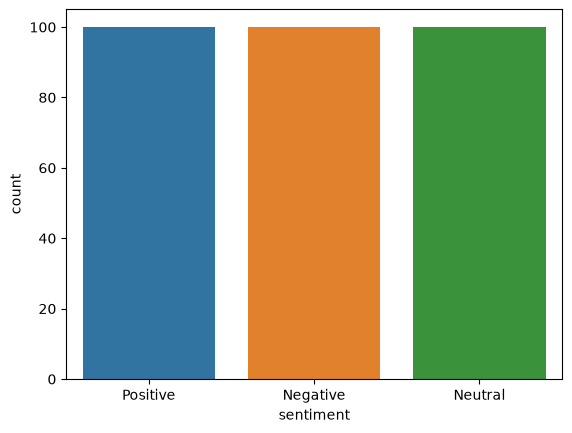

In [13]:
# class balance
sns.countplot(x="sentiment", data=df_cleaned, hue="sentiment")

<Axes: xlabel='sentiment', ylabel='word_count'>

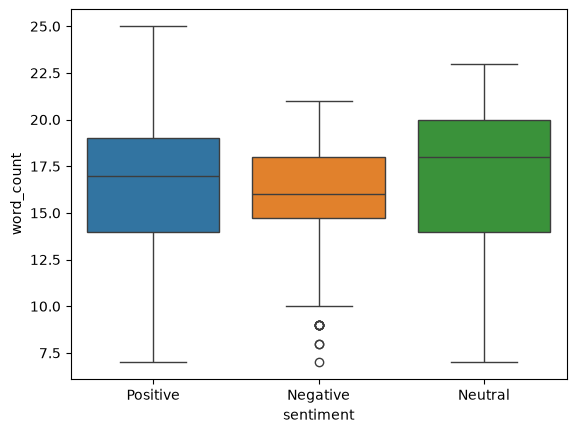

In [14]:
# review length per class
sns.boxplot(x="sentiment", y="word_count", data=df_cleaned, hue="sentiment")

([0, 1, 2, 3, 4, 5, 6, 7],
 [Text(0, 0, 'Books'),
  Text(1, 0, 'Travel'),
  Text(2, 0, 'Home & Kitchen'),
  Text(3, 0, 'Sports'),
  Text(4, 0, 'Food & Grocery'),
  Text(5, 0, 'Clothing'),
  Text(6, 0, 'Beauty'),
  Text(7, 0, 'Electronics')])

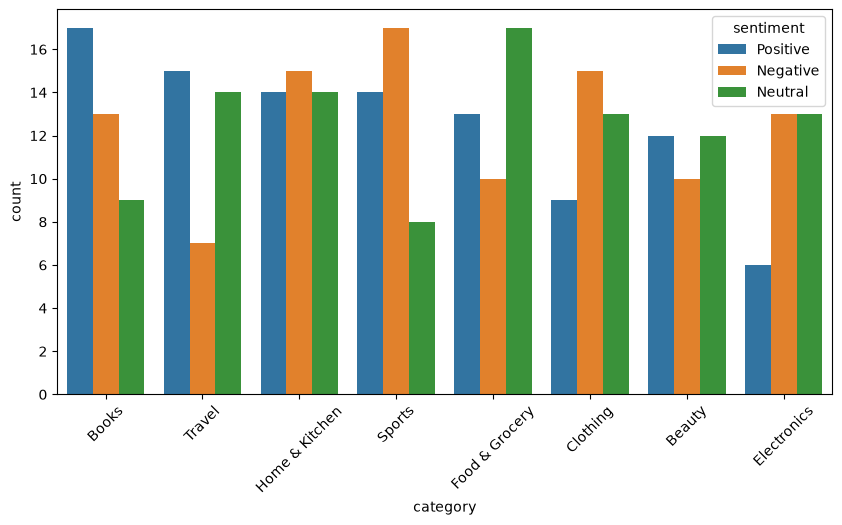

In [15]:
plt.figure(figsize=(10, 5))
sns.countplot(x="category", data=df_cleaned, hue="sentiment")
plt.xticks(rotation=45)

<Axes: xlabel='source', ylabel='count'>

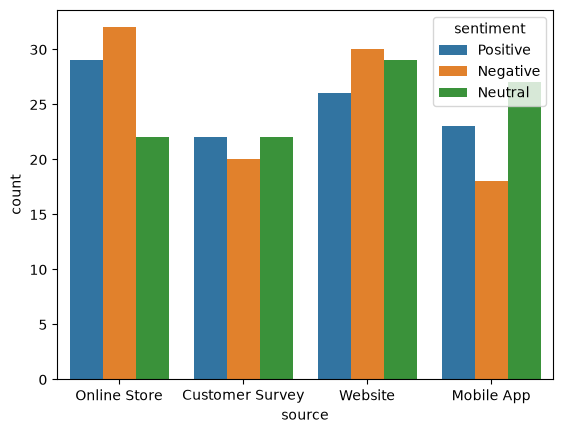

In [16]:
sns.countplot(x="source", data=df_cleaned, hue="sentiment")

- Classes are balanced (100 each), so accuracy is a fair metric here.
- Review lengths overlap a lot between classes, so length alone can't separate them.
- Category and source are spread evenly across sentiments, so they carry no signal and are not used as model input.

In [17]:
from sklearn.feature_extraction.text import CountVectorizer

# count every word, then add up per class
cv = CountVectorizer()
counts = cv.fit_transform(df_cleaned["review_text"])

words = pd.DataFrame(counts.toarray(), columns=cv.get_feature_names_out())
words["sentiment"] = df_cleaned["sentiment"].values

words.groupby("sentiment").sum().T.sort_values("Negative", ascending=False).head(10)

sentiment,Negative,Neutral,Positive
the,155,175,120
not,75,20,0
and,70,35,85
experience,65,0,50
it,60,25,75
would,50,0,50
was,40,25,35
with,35,5,30
am,30,20,30
frustrating,30,0,0


The top words are common ones (the, and, it). But "not" shows up 75 times in Negative, 20 in Neutral and never in Positive, so negation words matter.

## Step 3: Text preprocessing

- Lowercasing and punctuation are handled by the vectorizer itself.
- No digits, contractions or HTML in this data, so no extra cleaning is needed.
- Stopwords: sklearn's English list also removes "not", "no" and "never", which can flip the meaning. So a custom list is used that keeps them.
- Stemming/lemmatization is skipped. It needs extra libraries and a custom function, which makes saving the pipeline harder.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

# sklearn's list minus the negation words
my_stops = list(ENGLISH_STOP_WORDS - {"not", "no", "never"})

## Step 5: Train/test split

80/20 split. `stratify` keeps the class ratio the same in both parts. The test set is used only once, at the end.

In [19]:
from sklearn.model_selection import train_test_split

X = df_cleaned["review_text"]
y = df_cleaned["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

### Stopword choice

Comparing the three options with 5-fold cross-validation on the training set.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

stop_options = {"no stopword removal": None, "sklearn english list": "english", "custom list (keeps not, no, never)": my_stops}

for name, stops in stop_options.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words=stops)), ("model", LogisticRegression(max_iter=1000))])
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    print(name, scores.mean().round(3))

no stopword removal 0.992
sklearn english list 0.996
custom list (keeps not, no, never) 0.996


In [21]:
# does the stopword list break negation? (fit on all data, just for this demo)
tests = ["I would recommend it", "I would not recommend it", "This is not good"]

for name, stops in {"sklearn list": "english", "custom list": my_stops}.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words=stops, ngram_range=(1, 2))), ("model", LogisticRegression(max_iter=1000))])
    pipe.fit(X, y)
    print(name, pipe.predict(tests))

sklearn list ['Negative' 'Negative' 'Positive']
custom list ['Positive' 'Negative' 'Negative']


The scores are almost the same, because other words like "frustrating" already give the answer on this dataset. The check above shows the real difference: with sklearn's list the model gets "I would recommend it" and "This is not good" wrong. The custom list gets all three right, so it is the safer choice.

## Step 4 and 5: Bag of Words vs TF-IDF, and model comparison

Bag of Words counts words. TF-IDF gives less weight to words that appear in almost every review. Both are tried with three models, using 5-fold cross-validation on the training set.

In [22]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

vectorizers = {"BoW": CountVectorizer(stop_words=my_stops), "TF-IDF": TfidfVectorizer(stop_words=my_stops)}
models = {"LogReg": LogisticRegression(max_iter=1000), "NaiveBayes": MultinomialNB(), "LinearSVC": LinearSVC()}

for v_name, vec in vectorizers.items():
    for m_name, model in models.items():
        pipe = Pipeline([("vec", vec), ("model", model)])
        scores = cross_val_score(pipe, X_train, y_train, cv=5)
        print(v_name, m_name, scores.mean().round(3))

BoW LogReg 0.996
BoW NaiveBayes 0.996
BoW LinearSVC 1.0
TF-IDF LogReg 0.996
TF-IDF NaiveBayes 0.996
TF-IDF LinearSVC 1.0


All scores are between 0.996 and 1.0, too close to call a winner between BoW and TF-IDF. TF-IDF is used since it is the standard choice for text.

LinearSVC scores slightly higher, but it gives no probabilities and the app needs a confidence score. So Logistic Regression is the final model.

## Step 7: Cross-validation and tuning

Grid search with 5-fold cross-validation on the training set only. Macro F1 is used so every class counts equally.

In [23]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([("tfidf", TfidfVectorizer(stop_words=my_stops)), ("model", LogisticRegression(max_iter=1000))])

# C = regularization strength, ngram_range = single words or word pairs
params = {"tfidf__ngram_range": [(1, 1), (1, 2)], "model__C": [0.1, 1, 10]}

grid = GridSearchCV(pipe, params, cv=5, scoring="f1_macro")
grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_.round(3))

{'model__C': 1, 'tfidf__ngram_range': (1, 2)}
1.0


## Step 6: Evaluation on the test set

Done after tuning, so the test set is touched only once.

In [24]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score

y_pred = grid.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        20
     Neutral       1.00      1.00      1.00        20
    Positive       1.00      1.00      1.00        20

    accuracy                           1.00        60
   macro avg       1.00      1.00      1.00        60
weighted avg       1.00      1.00      1.00        60



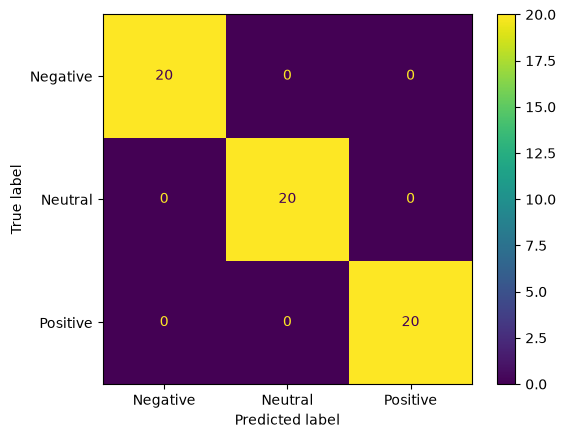

In [25]:
ConfusionMatrixDisplay.from_estimator(grid, X_test, y_test)

In [26]:
# one-vs-rest AUC for the 3 classes
roc_auc_score(y_test, grid.predict_proba(X_test), multi_class="ovr")

1.0

All 60 test reviews are correct, the confusion matrix is fully diagonal and AUC is 1.0.

This does not prove the model is excellent. Even after removing duplicates, the 300 reviews are built from only about 72 repeating sentences, so test sentences also appear in training. On real reviews the score would be lower.

## Step 8: Save the pipeline

The vectorizer and the model are saved together, so the app needs only one file and no retraining.

In [27]:
import joblib

joblib.dump(grid.best_estimator_, "sentiment_pipeline.pkl")

['sentiment_pipeline.pkl']

In [28]:
# load it back and try a new review
model = joblib.load("sentiment_pipeline.pkl")

model.predict(["I would not recommend this product"])

array(['Negative'], dtype=object)